In [11]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

'2'

In [6]:
!pip install scikeras

In [12]:
import re, time, random, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, ConfusionMatrixDisplay)
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

warnings.filterwarnings("ignore")


SEED = 42
random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

# Download the NLTK resources needed for stop words and lemmatization
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

True

In [44]:
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

In [45]:
df = pd.read_csv("https://raw.githubusercontent.com/rashakil-ds/Public-Datasets/refs/heads/main/amazon.csv")
df.head()

,reviewText,Positive
0,This is a one of the best apps acording to a b...,1
1,This is a pretty good version of the game for ...,1
2,this is a really cool game. there are a bunch ...,1
3,"This is a silly game and can be frustrating, b...",1
4,This is a terrific game on any pad. Hrs of fun...,1


In [46]:
data = df.copy()
data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   reviewText  20000 non-null  object
 1   Positive    20000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 312.6+ KB


In [47]:
data.isnull().sum()

,0
reviewText,0
Positive,0


Positive
0     4767
1    15233
Name: count, dtype: int64
Positive
0    23.84
1    76.17
Name: count, dtype: float64


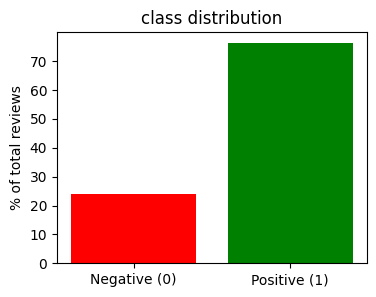

In [48]:
counts = data["Positive"].value_counts().sort_index()
print(counts)
print((counts / counts.sum()).round(4)*100)

plt.figure(figsize=(4, 3))
plt.bar(["Negative (0)", "Positive (1)"], (counts / counts.sum()).round(4)*100, color=["red","green"])
plt.ylabel("% of total reviews")
plt.title("class distribution")
plt.show()

In [49]:
data = data[["reviewText", "Positive"]].dropna().drop_duplicates(subset="reviewText")

In [50]:
data

,reviewText,Positive
0,This is a one of the best apps acording to a b...,1
1,This is a pretty good version of the game for ...,1
2,this is a really cool game. there are a bunch ...,1
3,"This is a silly game and can be frustrating, b...",1
4,This is a terrific game on any pad. Hrs of fun...,1
...,...,...
19995,this app is fricken stupid.it froze on the kin...,0
19996,Please add me!!!!! I need neighbors! Ginger101...,1
19997,love it! this game. is awesome. wish it had m...,1
19998,I love love love this app on my side of fashio...,1


In [51]:
data["pos"] = data["Positive"].astype(int)

In [52]:
del data["Positive"]
data.head()

,reviewText,pos
0,This is a one of the best apps acording to a b...,1
1,This is a pretty good version of the game for ...,1
2,this is a really cool game. there are a bunch ...,1
3,"This is a silly game and can be frustrating, b...",1
4,This is a terrific game on any pad. Hrs of fun...,1


In [53]:
KEEP_WORDS = {"not", "no", "nor", "never", "but", "very", "too"}
STOP_WORDS = set(stopwords.words("english")) - KEEP_WORDS
lemmatizer = WordNetLemmatizer()

In [54]:
def prepro(text):
  text = text.lower()
  text = re.sub(r"won't", "will not", text)
  text = re.sub(r"can't", "can not", text)
  text = re.sub(r"n't\b", " not", text)
  text = re.sub(r"[^a-z\s]", " ", text)
  tokens = text.split()
  tokens = [lemmatizer.lemmatize(token) for token in tokens]
  tokens = [token for token in tokens if token not in STOP_WORDS]
  return " ".join(tokens)

In [55]:
data["cleanText"] = data["reviewText"].apply(prepro)

In [ ]:
del data["reviewText"]


In [63]:
data.head()
data.shape

(20000, 2)

In [77]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    data["cleanText"],
    data["pos"],
    test_size=0.2,
    stratify=data["pos"],
    random_state=42
)

In [78]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=.25,
    stratify=y_train_val,
    random_state=42
)

In [79]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(12000,)
(4000,)
(12000,)
(4000,)


In [82]:
tfidf = TfidfVectorizer(min_df=2)

In [84]:
Xtr_tfidf = tfidf.fit_transform(X_train)
Xval_tfidf = tfidf.transform(X_val)
Xte_tfidf = tfidf.transform(X_test)

In [86]:
print(Xtr_tfidf.shape)

(12000, 5960)


In [87]:
from sklearn.model_selection import GridSearchCV
param_grids = {
    "Logistic Regression": {
        "C": [0.01, 0.1, 1.0, 10.0],
        "solver": ["liblinear", "lbfgs"]
    },
    "Naive Bayes": {
        "alpha": [0.001, 0.01, 0.1, 1.0]
    },
    "Linear SVM": {
        "C": [0.01, 0.1, 1.0, 10.0]
    }
}

In [88]:
basemodels = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Naive Bayes":         MultinomialNB(),
    "Linear SVM":          LinearSVC(class_weight="balanced"),
}

In [90]:
bestmodels = {}
cv_results = {}
val_results = {}

In [91]:
for name, model in basemodels.items():
    param_grid = param_grids[name]
    grid_search = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        cv=5,
        scoring='accuracy',
        n_jobs=-1,
        error_score='raise'
    )
    grid_search.fit(Xtr_tfidf, y_train)
    bestmodels[name] = grid_search.best_estimator_
    cv_results[name] = {
        "best_params": grid_search.best_params_,
        "best_score": grid_search.best_score_
    }

    val_score = grid_search.best_estimator_.score(Xval_tfidf, y_val)
    val_results[name] = val_score

    print(f"Model: {name}")
    print(grid_search.best_params_)
    print(f"CV score: {grid_search.best_score_:.2f}")
    print(f"validation socr: {val_score:.2f}\n")

Model: Logistic Regression
{'C': 10.0, 'solver': 'lbfgs'}
CV score: 0.89
validation socr: 0.89

Model: Naive Bayes
{'alpha': 0.1}
CV score: 0.87
validation socr: 0.87

Model: Linear SVM
{'C': 1.0}
CV score: 0.89
validation socr: 0.89



In [95]:
vectorizer = layers.TextVectorization(max_tokens=20000, output_sequence_length=40)

In [96]:
vectorizer.adapt(np.array(X_train.tolist()))

In [97]:
Xtr_seq = vectorizer(np.array(X_train.tolist())).numpy()
Xtr_seq

array([[  17,   20,  610, ...,    0,    0,    0],
       [  91, 1577, 1083, ...,    0,    0,    0],
       [ 811, 1674,  375, ...,    0,    0,    0],
       ...,
       [   7, 1360,    4, ...,    0,    0,    0],
       [  17,  151,   20, ...,    0,    0,    0],
       [   5,   57,  368, ...,    0,    0,    0]])

In [98]:
Xval_seq = vectorizer(np.array(X_val.tolist())).numpy()
Xte_seq = vectorizer(np.array(X_test.tolist())).numpy()

In [99]:
ytr = y_train.values

In [100]:
print(Xtr_seq.shape, Xval_seq.shape, Xte_seq.shape)

(12000, 40) (4000, 40) (4000, 40)


In [101]:
cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=ytr)

In [102]:
cw

array([2.0979021 , 0.65645514])

In [103]:
CLASS_WEIGHT = {0: cw[0], 1: cw[1]}

In [128]:
def build_lstm(units=64, dropout=0.2, lr=1e-3, embed_dim=100):
    model = models.Sequential([
        layers.Input(shape=(40,)),
        layers.Embedding(20000, embed_dim, mask_zero=True),
        layers.LSTM(units, dropout=dropout),
        layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(lr),
                  loss="binary_crossentropy", metrics=["accuracy"])
    return model

In [129]:
def early_stop():
    return callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)

In [135]:
lstm_results = []
best_val_loss, best_lstm, best_lstm_params, best_history = np.inf, None, None, None

In [131]:
tuned_models = {}
best_params = {}

In [136]:
for units, dropout in itertools.product([64, 128], [0.2, 0.4]):
    tf.keras.backend.clear_session()
    tf.random.set_seed(42)

    m = build_lstm(units=units, dropout=dropout)
    h = m.fit(
        Xtr_seq, ytr,
        validation_data=(Xval_seq, y_val),
        epochs=10,
        batch_size=32,
        class_weight=CLASS_WEIGHT,
        callbacks=[early_stop()],
        verbose=0
    )

    val_loss = min(h.history["val_loss"])
    lstm_results.append({
        "units": units,
        "dropout": dropout,
        "val_loss": val_loss,
        "val_accuracy": max(h.history["val_accuracy"]),
    })

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_lstm = m
        best_lstm_params = (units, dropout)
        best_history = h

print(pd.DataFrame(lstm_results).round(2))
print(best_lstm_params)

tuned_models["LSTM"] = best_lstm
best_params["LSTM"] = {"units": best_lstm_params[0], "dropout": best_lstm_params[1]}

   units  dropout  val_loss  val_accuracy
0     64      0.2      0.28          0.89
1     64      0.4      0.28          0.89
2    128      0.2      0.28          0.89
3    128      0.4      0.27          0.89
(128, 0.4)


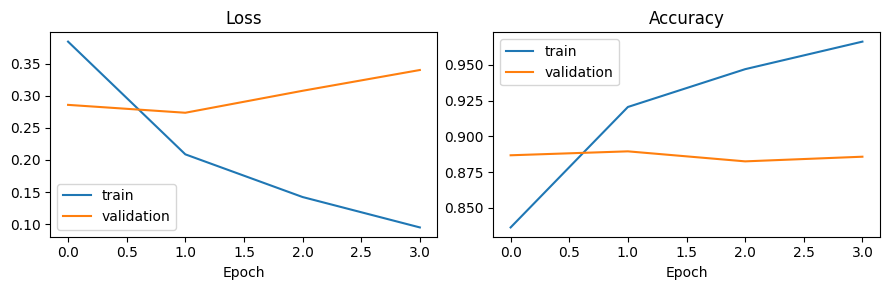

In [137]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].plot(best_history.history["loss"], label="train")
axes[0].plot(best_history.history["val_loss"], label="validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[1].plot(best_history.history["accuracy"], label="train")
axes[1].plot(best_history.history["val_accuracy"], label="validation")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout();plt.show()

In [106]:
# lstm = build_lstm()

In [108]:
# history = lstm.fit(
#     Xtr_seq, ytr,
#     validation_data=(Xval_seq, y_val),
#     epochs=10,
#     batch_size=32,
#     class_weight=CLASS_WEIGHT,
#     callbacks=[early_stop()],
#     verbose=1
# )

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 26s 58ms/step - accuracy: 0.8453 - loss: 0.3757 - val_accuracy: 0.8857 - val_loss: 0.2822
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 28s 74ms/step - accuracy: 0.9235 - loss: 0.1981 - val_accuracy: 0.8898 - val_loss: 0.2824
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 29s 42ms/step - accuracy: 0.9532 - loss: 0.1231 - val_accuracy: 0.8855 - val_loss: 0.3268


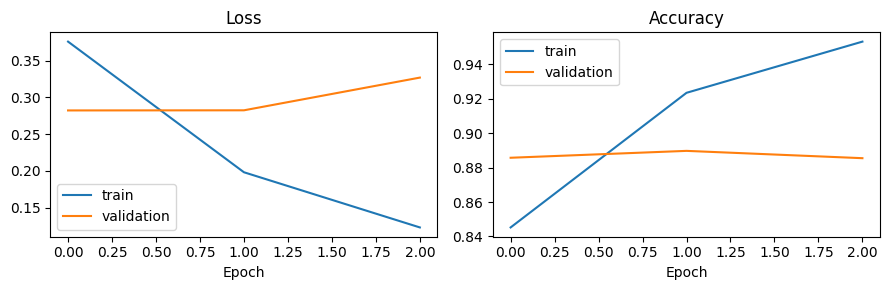

In [109]:
# fig, axes = plt.subplots(1, 2, figsize=(9, 3))
# axes[0].plot(history.history["loss"], label="train")
# axes[0].plot(history.history["val_loss"], label="validation")
# axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()
# axes[1].plot(history.history["accuracy"], label="train")
# axes[1].plot(history.history["val_accuracy"], label="validation")
# axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend()
# plt.tight_layout(); plt.show()

In [139]:
all_models = {
    "Logistic Regression": bestmodels["Logistic Regression"],
    "Naive Bayes": bestmodels["Naive Bayes"],
    "Linear SVM": bestmodels["Linear SVM"],
    "LSTM": best_lstm
}
all_predictions = {}
all_metrics = {}

In [140]:
for name, model in all_models.items():
    if name == "LSTM":
        pred = (model.predict(Xte_seq, verbose=0).ravel() >= 0.5).astype(int)
    else:
        pred = model.predict(Xte_tfidf)
    all_predictions[name] = pred
    all_metrics[name] = {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-score": f1_score(y_test, pred)
    }

In [141]:
all_default = {**basemodels, "LSTM": best_lstm}

In [121]:
default_preds = {}
for name, m in all_default.items():
    if name == "LSTM":
        default_preds[name] = (m.predict(Xte_seq, verbose=0).ravel() >= 0.5).astype(int)
    else:
        m.fit(Xtr_tfidf, y_train)
        default_preds[name] = m.predict(Xte_tfidf)

default_results = pd.DataFrame({
    name: {
        "Accuracy": accuracy_score(y_test, p),
        "Precision": precision_score(y_test, p),
        "Recall": recall_score(y_test, p),
        "F1-score": f1_score(y_test, p)
    }
    for name, p in default_preds.items()
}).T
default_results.round(2).sort_values("Accuracy", ascending=False)

,Accuracy,Precision,Recall,F1-score
Logistic Regression,0.88,0.96,0.88,0.92
Linear SVM,0.88,0.94,0.90,0.92
LSTM,0.87,0.96,0.88,0.91
Naive Bayes,0.84,0.83,0.99,0.91


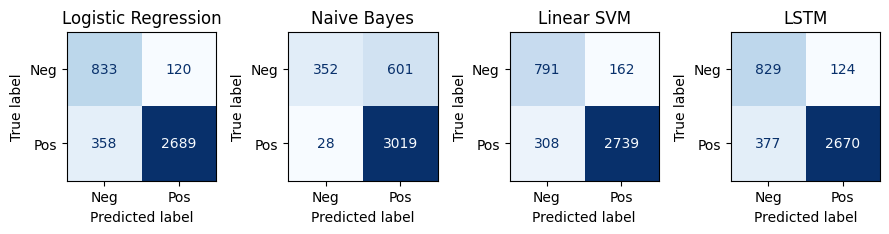

In [142]:
fig, axes = plt.subplots(1, 4, figsize=(9, 10))
for ax, (name, pred) in zip(axes.ravel(), default_preds.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred,
        display_labels=["Neg", "Pos"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [143]:
all_default

{'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000),
 'Naive Bayes': MultinomialNB(),
 'Linear SVM': LinearSVC(class_weight='balanced'),
 'LSTM': <Sequential name=sequential, built=True>}

In [144]:
all_predictions

{'Logistic Regression': array([1, 1, 0, ..., 1, 1, 1]),
 'Naive Bayes': array([1, 1, 1, ..., 1, 1, 1]),
 'Linear SVM': array([1, 1, 0, ..., 1, 1, 1]),
 'LSTM': array([1, 1, 0, ..., 1, 1, 1])}

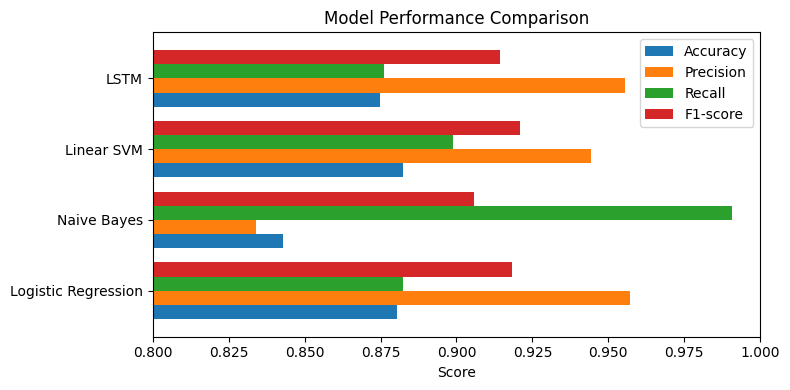

In [160]:
fig, ax = plt.subplots(figsize=(8, 4))
default_results.plot(kind="barh", ax=ax, width=0.8)

# 3. Styling
ax.set_title("Model Performance Comparison")
ax.set_xlabel("Score")
ax.set_xlim(0.8, 1)
ax.legend(loc="best")


plt.tight_layout()
plt.show()

### Summary of findings
- Four models were trained and compared: Logistic Regression, Naive Bayes, SVM and an LSTM.
- Classical models with TF-IDF are fast and usually very strong on short reviews, because sentiment is mostly carried by individual words and short phrases.
- Hyperparameter tuning (especially adding bigrams) usually improves the classical models. The LSTM often gains little from tuning.
- The cell above shows which model had the best F1-score in this run.

### Challenges
- **Preprocessing:** standard stop-word lists contain negations such as "not" and "no", which flip the meaning of a review, so they were kept. Contractions like "didn't" had to be expanded before removing punctuation.
- **Class imbalance:** accuracy alone can look good by predicting "positive" for everything, so class weights and precision, recall and F1 were used.
- **Training:** the LSTM needs much more time than the classical models and starts to overfit after a few epochs, so early stopping was necessary.
- **Evaluation:** tuning was done with cross-validation / a validation split on the training data only, so the test set stayed unseen.

### Lessons learned
- Start with a simple, fast baseline (TF-IDF + Logistic Regression) before trying deep learning.
- Evaluate with several metrics, not accuracy alone, when classes are imbalanced.
- Fit vectorizers on the training data only to avoid data leakage.
- More complex models are not always better, especially on small and short-text datasets.
- Possible improvements: pretrained embeddings (Word2Vec/GloVe), a GRU or bidirectional LSTM, and more tuning.